In [1]:
import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
import numpy as np
import requests
import time
import torch
import torch.nn as nn
from transformers import AutoModelForCausalLM, AutoTokenizer

# gráficos vectoriales
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

---

#### **Diseño experimental: Moby Dick y modelos paralelos**

A continuación, vamos a tokenizar el libro *Moby Dick* disponible en Project Gutenberg y cargaremos dos instancias del modelo en variables separadas. La razón de tener dos modelos independientes es que congelaremos partes estratégicas en uno de ellos, mientras dejamos el otro completamente entrenable.

Este enfoque experimental resulta sumamente interesante porque ambos modelos parten de idénticas condiciones iniciales y se alimentarán con exactamente los mismos datos y en el mismo orden. La **única variable de diferencia** entre ambos será que uno mantendrá ciertas matrices de pesos congeladas, permitiéndonos contrastar directamente el impacto de la técnica en el aprendizaje.

In [2]:
# Tokenitzador d'Eleuther
tokenizer = AutoTokenizer.from_pretrained('EleutherAI/gpt-neo-125m')
tokenizer.pad_token_id = tokenizer.encode(' ')[0]

# -> GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# Carregar dos GPT-Neo i enviar-los a la GPU
modelFreeze = AutoModelForCausalLM.from_pretrained(
    'EleutherAI/gpt-neo-125m'
).to(device)
modelTrain = AutoModelForCausalLM.from_pretrained(
    'EleutherAI/gpt-neo-125m'
).to(device)

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/357 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## Cargar data

In [3]:
# Moby Dick
text = requests.get('https://www.gutenberg.org/cache/epub/2701/pg2701.txt').text
tokens = tokenizer.encode(text, return_tensors='pt')[0]

# resumen
print(
    f'Moby Dick tiene {len(tokens):,} tokens, de los cuales'
    f' {len(torch.unique(tokens)):,} son únicos'
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (354334 > 2048). Running this sequence through the model will result in indexing errors


Moby Dick tiene 354,334 tokens, de los cuales 17,258 son únicos


### mostrar los tokens mas frecuentes

los tokens mas comunes son los tokens esperados que se encuentran en cualquier texto. Pero tambien vemos palabras como Ballena (Whale), Nave (Ship) etc. Que no se esperarian ver con mucha frecuencia en otros textos

In [5]:
# Encontrar los tokens únicos y sus conteos de frecuencia
uniq, counts = np.unique(tokens, return_counts=True)
freqidx = np.argsort(counts)[::-1]
top100 = uniq[freqidx[:100]]

# Mostrar los 100 tokens más frecuentes en el texto de Moby Dick
for t in top100:
  print(
      f'Token {t:5} appears {torch.sum(tokens==t):4} times and is'
      f' "{tokenizer.decode([t])}"'
  )

"
Token   198 appears 22331 times and is "
"
Token    11 appears 19216 times and is ","
Token   262 appears 13157 times and is " the"
Token    13 appears 7903 times and is "."
Token   286 appears 6402 times and is " of"
Token   290 appears 5708 times and is " and"
Token   447 appears 5360 times and is "�"
Token   257 appears 4533 times and is " a"
Token   284 appears 4437 times and is " to"
Token    26 appears 4167 times and is ";"
Token   287 appears 3853 times and is " in"
Token   247 appears 2796 times and is "�"
Token   326 appears 2749 times and is " that"
Token    12 appears 2584 times and is "-"
Token    82 appears 2394 times and is "s"
Token   465 appears 2351 times and is " his"
Token   340 appears 2108 times and is " it"
Token   314 appears 1869 times and is " I"
Token     0 appears 1763 times and is "!"
Token   318 appears 1657 times and is " is"
Token   250 appears 1628 times and is "�"
Token   351 appears 1600 times and is " with"
Token   339 appears 1596 times and is " he

In [6]:
numreps = 10  # número de repeticiones aleatorias
numtoks = 100  # longitud de salida

# inicializar
tokenUsage = np.zeros((2, 2))  # [ pre/post , Freeze/Train ]

# tokens de inicio aleatorios
randstarts = torch.randint(
    tokenizer.vocab_size, (numreps, 1)
).to(device)

# FREEZE: generar y almacenar tokens
outFreeze = modelFreeze.generate(
    randstarts,
    min_length=numtoks + 1,
    max_length=numtoks + 1,
    do_sample=True,
    pad_token_id=tokenizer.pad_token_id,
).cpu()
genTokensFreeze = outFreeze[:, 1:].reshape(-1)

# TRAIN: igual que el anterior :)
outTrain = modelTrain.generate(
    randstarts,
    min_length=numtoks + 1,
    max_length=numtoks + 1,
    do_sample=True,
    pad_token_id=tokenizer.pad_token_id,
).cpu()
genTokensTrain = outTrain[:, 1:].reshape(-1)

# calcular el porcentaje
tokenUsage[0, 0] = np.mean(100 * np.isin(genTokensFreeze, top100))
tokenUsage[0, 1] = np.mean(100 * np.isin(genTokensTrain, top100))

In [7]:
tokenUsage

array([[45.7, 45.1],
       [ 0. ,  0. ]])

45.7% Y 45.1% Son tokens generados por estos modelos base preentrenados son tokens que tambien aparecen en el top 100 de moby Dick. Que ocurrira despues de aplicar el fine tunning?

In [8]:
# Vamos a hacer una Congelación de vision de precision dirigida (Targeted Precision Freezing)

### **Estrategia de ajuste selectivo y dirigido**

En concreto, el objetivo es entrenar únicamente los bloques de atención, restringiéndolo exclusivamente a las capas del transformador número seis y superiores. Dicho de otro modo, esto equivale a congelar la totalidad del modelo a excepción de los pesos de atención en los bloques avanzados del transformador. De este modo, implementamos un *fine-tuning* altamente selectivo y dirigido con precisión milimétrica.

---

Para lograrlo, es necesario aislar específicamente las matrices de pesos de consulta, clave y valor ($q, k, v$) en los bloques correspondientes, evitando congelar por error la matriz $w_0$. Esta última actúa como la transformación lineal encargada de combinar los resultados de las distintas cabezas de atención antes de enviarlos a la red de alimentación directa (*MLP*). Por lo tanto, la estrategia consiste en no entrenar la matriz $w_0$ ni las matrices $q, k, v$ en las capas del cero al cinco.

In [9]:
for name, param in modelFreeze.named_parameters():
  splitstr = name.split('.')
  print(splitstr)

['transformer', 'wte', 'weight']
['transformer', 'wpe', 'weight']
['transformer', 'h', '0', 'ln_1', 'weight']
['transformer', 'h', '0', 'ln_1', 'bias']
['transformer', 'h', '0', 'attn', 'attention', 'k_proj', 'weight']
['transformer', 'h', '0', 'attn', 'attention', 'v_proj', 'weight']
['transformer', 'h', '0', 'attn', 'attention', 'q_proj', 'weight']
['transformer', 'h', '0', 'attn', 'attention', 'out_proj', 'weight']
['transformer', 'h', '0', 'attn', 'attention', 'out_proj', 'bias']
['transformer', 'h', '0', 'ln_2', 'weight']
['transformer', 'h', '0', 'ln_2', 'bias']
['transformer', 'h', '0', 'mlp', 'c_fc', 'weight']
['transformer', 'h', '0', 'mlp', 'c_fc', 'bias']
['transformer', 'h', '0', 'mlp', 'c_proj', 'weight']
['transformer', 'h', '0', 'mlp', 'c_proj', 'bias']
['transformer', 'h', '1', 'ln_1', 'weight']
['transformer', 'h', '1', 'ln_1', 'bias']
['transformer', 'h', '1', 'attn', 'attention', 'k_proj', 'weight']
['transformer', 'h', '1', 'attn', 'attention', 'v_proj', 'weight']
[

In [10]:
# TEST: identificar pesos QVK en capas > 5
for name, param in modelFreeze.named_parameters():
  splitstr = name.split('.')
  if (len(splitstr) > 5) and (splitstr[3] == 'attn'):
    if (int(splitstr[2]) > 5) and (splitstr[5][0] in 'qvk'):
      print(name)

transformer.h.6.attn.attention.k_proj.weight
transformer.h.6.attn.attention.v_proj.weight
transformer.h.6.attn.attention.q_proj.weight
transformer.h.7.attn.attention.k_proj.weight
transformer.h.7.attn.attention.v_proj.weight
transformer.h.7.attn.attention.q_proj.weight
transformer.h.8.attn.attention.k_proj.weight
transformer.h.8.attn.attention.v_proj.weight
transformer.h.8.attn.attention.q_proj.weight
transformer.h.9.attn.attention.k_proj.weight
transformer.h.9.attn.attention.v_proj.weight
transformer.h.9.attn.attention.q_proj.weight
transformer.h.10.attn.attention.k_proj.weight
transformer.h.10.attn.attention.v_proj.weight
transformer.h.10.attn.attention.q_proj.weight
transformer.h.11.attn.attention.k_proj.weight
transformer.h.11.attn.attention.v_proj.weight
transformer.h.11.attn.attention.q_proj.weight


In [11]:
for name, param in modelFreeze.named_parameters():

  # dividir el nombre por puntos
  splitstr = name.split('.')

  # ver si esto se ajusta a nuestro filtro
  if (len(splitstr) > 5) and (splitstr[3] == 'attn'):
    if (int(splitstr[2]) > 5) and (splitstr[5][0] in 'qvk'):
      param.requires_grad = True
      print(
          f'+++ La capa {name} es entrenable (.requires_grad ='
          f' {param.requires_grad})'
      )

  # de lo contrario, congelar la capa
  else:
    param.requires_grad = False
    print(
        f'--- La capa {name} está congelada (.requires_grad ='
        f' {param.requires_grad}).'
    )

--- La capa transformer.wte.weight está congelada (.requires_grad = False).
--- La capa transformer.wpe.weight está congelada (.requires_grad = False).
--- La capa transformer.h.0.ln_1.weight está congelada (.requires_grad = False).
--- La capa transformer.h.0.ln_1.bias está congelada (.requires_grad = False).
--- La capa transformer.h.0.ln_2.weight está congelada (.requires_grad = False).
--- La capa transformer.h.0.ln_2.bias está congelada (.requires_grad = False).
--- La capa transformer.h.0.mlp.c_fc.weight está congelada (.requires_grad = False).
--- La capa transformer.h.0.mlp.c_fc.bias está congelada (.requires_grad = False).
--- La capa transformer.h.0.mlp.c_proj.weight está congelada (.requires_grad = False).
--- La capa transformer.h.0.mlp.c_proj.bias está congelada (.requires_grad = False).
--- La capa transformer.h.1.ln_1.weight está congelada (.requires_grad = False).
--- La capa transformer.h.1.ln_1.bias está congelada (.requires_grad = False).
--- La capa transformer.h.1.

1. **Congelación de capas base (Capas 0 a 5):**
   - Se desactivan los gradientes (`requires_grad = False`) en todos los bloques iniciales del transformador.
   - **Objetivo:** Preservar la sintaxis fundamental, el conocimiento semántico de bajo nivel y las representaciones lingüísticas generales ya aprendidas durante el preentrenamiento.

2. **Ajuste quirúrgico en bloques avanzados (Capas 6 a 11):**
   - En esta segunda mitad de la red, mantenemos congeladas las redes de alimentación directa (*MLP*) y las normalizaciones, pero **habilitamos los gradientes (`requires_grad = True`) exclusivamente en las matrices de proyección de atención**: Consultas (`q_proj`), Claves (`k_proj`) y Valores (`v_proj`).
   - **Objetivo:** Permitir que el modelo adapte dinámicamente cómo pondera y relaciona los tokens en un contexto profundo, sin alterar la forma en que se combinan globalmente dichas perspectivas (protegiendo la matriz de salida $w_0$).

3. **Incrustaciones y capas finales congeladas:**
   - Los embeddings de texto (`wte`), de posición (`wpe`) y la capa de normalización final (`ln_f`) permanecen intactos.

In [13]:
# Tenemos beneficio para tener una tasa superior de epochs (como ya los pesos estan congelados)

In [14]:
# Vamos a cronometrar el tiempo para cada iteración

## Entrenar los modelos

In [15]:
# Optimizador para el modelo con capas congeladas
optimizerFreeze = torch.optim.AdamW(modelFreeze.parameters(), lr=0.0005)

# Optimizador para el modelo de entrenamiento completo
optimizerTrain = torch.optim.AdamW(modelTrain.parameters(), lr=0.0005)

In [16]:
# parámetros de entrenamiento
seq_len = 256  # longitud máxima de la secuencia
batch_size = 16
num_samples = 474

In [17]:
# inicializar pérdidas
losses = np.zeros((num_samples, 2))
delta_norm_em = np.zeros((num_samples, 2))

# y tiempos de cómputo
timeTrain = 0
timeFreeze = 0

# capturar los pesos iniciales de la capa k_proj para comparación
prev_emFreeze = (
    modelFreeze.transformer.h[6]
    .attn.attention.k_proj.weight.detach()
    .clone()
)
prev_emTrain = (
    modelTrain.transformer.h[6].attn.attention.k_proj.weight.detach().clone()
)

# ¡y ejecutar el entrenamiento!
for sampli in range(num_samples):

  # obtener un lote de datos
  ix = torch.randint(len(tokens) - seq_len, size=(batch_size,))
  X = tokens[ix[:, None] + torch.arange(seq_len)].to(device)

  ### --- Fine-tuning con capas congeladas (FREEZE) ---
  # propagación hacia adelante y obtención de la pérdida
  start_time = time.time()  # iniciar el cronómetro
  modelFreeze.zero_grad()
  outputs = modelFreeze(X, labels=X)

  # propagación hacia atrás y almacenamiento de la pérdida
  outputs.loss.backward()
  optimizerFreeze.step()
  losses[sampli, 0] = outputs.loss.item()
  timeFreeze += time.time() - start_time  # detener el cronómetro y sumar
  ### --------------------------------------------------

  ### --- Fine-tuning del modelo completo (TRAIN) ---
  # propagación hacia adelante y obtención de la pérdida
  start_time = time.time()  # iniciar el cronómetro
  modelTrain.zero_grad()
  outputs = modelTrain(X, labels=X)

  # propagación hacia atrás y almacenamiento de la pérdida
  outputs.loss.backward()
  optimizerTrain.step()
  losses[sampli, 1] = outputs.loss.item()
  timeTrain += time.time() - start_time  # detener el cronómetro y sumar
  ### -----------------------------------------------

  # norma de la matriz para evaluar el cambio en la capa de atención
  delta_norm_em[sampli, 0] = torch.norm(
      modelFreeze.transformer.h[6].attn.attention.k_proj.weight.detach()
      - prev_emFreeze
  )
  prev_emFreeze = (
      modelFreeze.transformer.h[6]
      .attn.attention.k_proj.weight.detach()
      .clone()
  )

  delta_norm_em[sampli, 1] = torch.norm(
      modelTrain.transformer.h[6].attn.attention.k_proj.weight.detach()
      - prev_emTrain
  )
  prev_emTrain = (
      modelTrain.transformer.h[6].attn.attention.k_proj.weight.detach().clone()
  )

  # actualizar la visualización del progreso
  if sampli % 37 == 0:
    print(
        f'Muestra {sampli:4}/{num_samples}, pérdidas (Congelado/Entrenable):'
        f' {losses[sampli, 0]:.4f} / {losses[sampli, 1]:.4f}'
    )

Muestra    0/474, pérdidas (Congelado/Entrenable): 3.4600 / 3.4600
Muestra   37/474, pérdidas (Congelado/Entrenable): 3.4782 / 3.5868
Muestra   74/474, pérdidas (Congelado/Entrenable): 3.3717 / 3.1312
Muestra  111/474, pérdidas (Congelado/Entrenable): 3.1083 / 2.6646
Muestra  148/474, pérdidas (Congelado/Entrenable): 3.0652 / 2.4363
Muestra  185/474, pérdidas (Congelado/Entrenable): 3.0468 / 2.2587
Muestra  222/474, pérdidas (Congelado/Entrenable): 3.0187 / 2.4410
Muestra  259/474, pérdidas (Congelado/Entrenable): 3.0730 / 2.1567
Muestra  296/474, pérdidas (Congelado/Entrenable): 2.9243 / 1.9565
Muestra  333/474, pérdidas (Congelado/Entrenable): 2.7795 / 1.7332
Muestra  370/474, pérdidas (Congelado/Entrenable): 2.6340 / 1.5268
Muestra  407/474, pérdidas (Congelado/Entrenable): 2.3693 / 1.0563
Muestra  444/474, pérdidas (Congelado/Entrenable): 2.4011 / 1.0809


In [18]:
## Vamos a graficar las perdidas del modelo congelado y del modelo totalmente entrenable

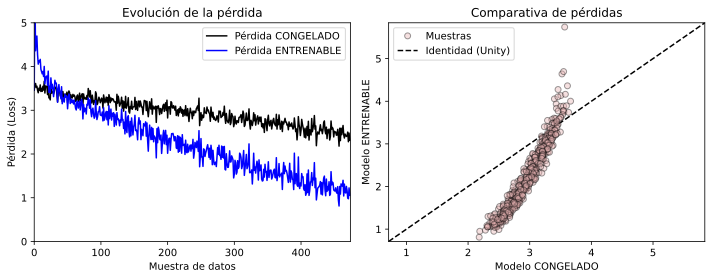

In [19]:
# graficar las pérdidas
_, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(losses[:, 0], 'k', markersize=8, label='Pérdida CONGELADO')
axs[0].plot(losses[:, 1], 'b', markersize=8, label='Pérdida ENTRENABLE')
axs[0].legend()
axs[0].set(
    ylim=[0, 5],
    xlabel='Muestra de datos',
    ylabel='Pérdida (Loss)',
    xlim=[0, num_samples],
    title='Evolución de la pérdida',
)

axs[1].plot(
    losses[:, 0],
    losses[:, 1],
    'ko',
    markerfacecolor=[0.9, 0.7, 0.7],
    alpha=0.4,
    label='Muestras',
)
xylim = [np.min(losses) - 0.1, np.max(losses) + 0.1]
axs[1].plot(xylim, xylim, 'k--', zorder=-3, label='Identidad (Unity)')
axs[1].set(
    xlabel='Modelo CONGELADO',
    ylabel='Modelo ENTRENABLE',
    title='Comparativa de pérdidas',
    xlim=xylim,
    ylim=xylim,
)
axs[1].legend()

plt.tight_layout()
plt.show()

### Análisis y Reflexión Crítica de los Resultados

Vemos que el modelo totalmente entrenable tiene una pérdida mucho más profunda y pronunciada, y al final es considerablemente menor. El modelo congelado —que en realidad está parcialmente congelado, o en su mayor parte— aprende un poco: cae de `3.4600` a `2.4011`, pero no de forma tan impresionante como la línea azul. Esto no es sorprendente, pero nos permite plantearnos la pregunta crítica: **¿cuál de los dos modelos es mejor?**

Si repasamos el aprendizaje profundo enfocado en la categorización o la clasificación, podríamos decir que la línea azul es superior porque las pérdidas son altas y queremos minimizarlas. Por otro lado, al trabajar con un modelo generativo y realizar un proceso de *fine-tuning*, no está tan claro que minimizar la pérdida de entrenamiento sea necesariamente la mejor manera de evaluar el rendimiento del modelo.

Por supuesto, queremos que las pérdidas sean pequeñas y disminuyan a lo largo del ajuste, pero en realidad la gente utiliza modelos generativos para crear texto, y estas cifras puras no nos dicen nada sobre la coherencia, la fluidez y la sensibilidad del modelo cuando está generando lenguaje de manera autónoma.

Además, en el gráfico se observa que la pérdida de formación comenzó siendo mayor; de hecho, al principio eran prácticamente iguales, pero la del modelo totalmente entrenable fue un punto más alta. La razón de esto es que todo el modelo —cada parámetro y cada peso entrenable— se está ajustando, desplazando y adaptando simultáneamente. Por lo tanto, el modelo cambia mucho al principio, mientras que el modelo parcialmente congelado cambia muy poco, lo que lo hace un poco más estable en las etapas iniciales del entrenamiento.

---

### Análisis del Gráfico de Dispersión (*Unity Plot*)

En este gráfico tenemos el modelo congelado (o parcialmente congelado) en el eje X y el modelo totalmente entrenable en el eje Y, junto con la línea de identidad que nos indica que cualquier punto situado exactamente sobre ella representaría un comportamiento idéntico en ambos modelos.

Por ejemplo, si no congeláramos nada del modelo y solo tuviéramos dos copias idénticas del mismo, esperaríamos que todos los puntos se situaran perfectamente sobre la diagonal. El hecho de que no estén ahí nos demuestra que existen dinámicas diferentes entre ellos. En particular, cualquier punto por debajo de la diagonal nos indica que el modelo congelado tuvo mayores pérdidas.

Por ejemplo, cuando el modelo congelado tenía una pérdida de 3, el modelo entrenable tenía una pérdida de 2 (o un poco por encima de 2). Es por esto que el modelo congelado acumuló mayores pérdidas, a pesar de que los datos de entrenamiento a los que se enfrentaron fueron idénticos. Y es precisamente en estos puntos específicos donde el modelo totalmente entrenable experimentó pérdidas mayores en comparación con el congelado, tal como se mencionó al principio.

## Generar tokens al azar

In [20]:
# FREEZE: generar y almacenar tokens
outFreeze = modelFreeze.generate(
    randstarts,
    min_length=numtoks + 1,
    max_length=numtoks + 1,
    do_sample=True,
    pad_token_id=tokenizer.pad_token_id,
).cpu()
genTokensFreeze = outFreeze[:, 1:].reshape(-1)

# TRAIN: igual que el anterior :)
outTrain = modelTrain.generate(
    randstarts,
    min_length=numtoks + 1,
    max_length=numtoks + 1,
    do_sample=True,
    pad_token_id=tokenizer.pad_token_id,
).cpu()
genTokensTrain = outTrain[:, 1:].reshape(-1)

# calcular el porcentaje
tokenUsage[1, 0] = np.mean(100 * np.isin(genTokensFreeze, top100))
tokenUsage[1, 1] = np.mean(100 * np.isin(genTokensTrain, top100))

print(tokenizer.decode(genTokensTrain))

. If upon first
apprehensively seeing but a glimpse of the whale, my stepmother had
deliriously dashed and accompanies the body; if upon first
apprehensively seeing but a glimpse of the whale, my stepmother had, in
a degree, perceived that it was a huge whitefish, and that the white
fish, at first sight, seemed quite distinct from the other porpoises.

“Do you see,. Forgetful of his crew, the Lakeman made
him present to poor Queequeg all panting and panting and panting and
sore exhausted. His knee-joint was soon over him, and he gave in fast
there, spite of his strong arm that resisted him; a line-of-battle-ship
coiling him up and down, up and down; up and lance in hand; up and
down; and-heads; but to the same end we sail; to the
end, we bow-point. So with our ivory boat and harpoon—almost
entire—and attached to our main-top this peculisome strip of junk, we
stand alongside, and the strange tail of the sperm whale curled high
before our very top. A sweet, grassy, scraggy end of it, lik

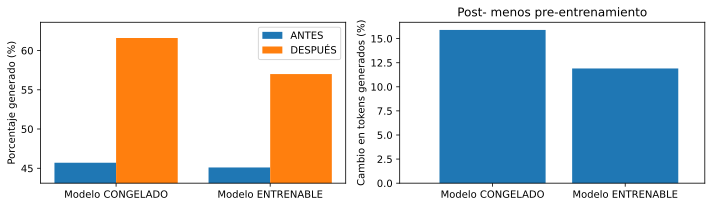

In [21]:
# ¡visualizar los resultados!
_, axs = plt.subplots(1, 2, figsize=(10, 3))

# mostrar el uso de tokens antes del entrenamiento
axs[0].bar([0.8, 1.8], tokenUsage[0, :], width=0.4, label='ANTES')
axs[0].bar([1.2, 2.2], tokenUsage[1, :], width=0.4, label='DESPUÉS')
axs[0].set(
    ylim=[min(tokenUsage.flatten()) - 2, max(tokenUsage.flatten()) + 2],
    xticks=[1, 2],
    xticklabels=['Modelo CONGELADO', 'Modelo ENTRENABLE'],
    ylabel='Porcentaje generado (%)',
)
axs[0].legend()

axs[1].bar([1, 2], np.diff(tokenUsage, axis=0)[0])
axs[1].set(
    xticks=[1, 2],
    xlim=[0.3, 2.6],
    xticklabels=['Modelo CONGELADO', 'Modelo ENTRENABLE'],
    ylabel='Cambio en tokens generados (%)',
    title='Post- menos pre-entrenamiento',
)

plt.tight_layout()
plt.show()

### Análisis del Uso de Tokens y Generación

Vemos que en ambos casos las barras naranjas son mayores que las azules, lo que nos indica que ambos modelos seleccionan una mayor proporción de tokens de *Moby Dick* después del *fine-tuning* que antes. De hecho, observamos que esta proporción es mayor para el modelo con congelación parcial.

A priori, esto no sigue la dirección esperada del efecto: se habría anticipado que el modelo totalmente entrenable presentara una mayor cantidad de tokens de *Moby Dick* en comparación con el modelo parcialmente congelado. Sin embargo, este resultado refleja la propia naturaleza del muestreo aleatorio y la actividad estocástica inherente a la generación de texto.

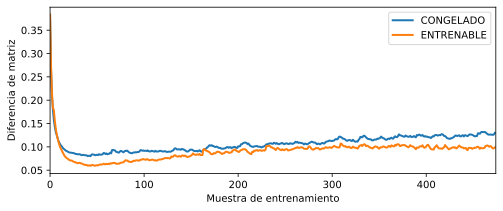

In [22]:
# ¿cómo cambiaron los pesos de los embeddings/matrices?
plt.figure(figsize=(8, 3))

plt.plot(delta_norm_em[:, 0], linewidth=2, label='CONGELADO')
plt.plot(delta_norm_em[:, 1], linewidth=2, label='ENTRENABLE')

plt.legend()
plt.gca().set(
    xlim=[0, num_samples],
    xlabel='Muestra de entrenamiento',
    ylabel='Diferencia de matriz',
)
plt.show()

### Análisis de la Dinámica de Cambio en las Matrices de Peso

Vemos que los valores empiezan siendo muy altos, después sufren una caída en picada y posteriormente vuelven a subir poco a poco. Esto nos indica que la matriz de pesos (recordando que se trata de una matriz de pesos de un bloque de atención específico) está cambiando drásticamente desde el principio.

Durante el primer par de iteraciones de entrenamiento, esta matriz experimenta modificaciones muy intensas, para luego dejar de cambiar o hacerlo de forma mucho más lenta, lo que significa que gran parte del aprendizaje importante ya ha tenido lugar en esa etapa inicial.

El hecho de que la línea azul (que corresponde al modelo mayoritariamente congelado) esté por encima de la línea naranja (que corresponde al modelo totalmente entrenable) nos indica que la mayoría de los cambios del modelo se concentran precisamente en estas capas que se mantienen entrenables. No es de extrañar, ya que el modelo tiene que esforzarse en ajustar sus ponderaciones para predecir mejor los siguientes tokens.

¿Cómo logra esto? En el modelo totalmente entrenable la carga se reparte entre 124 millones de parámetros; sin embargo, en el modelo congelado solo se entrenan un par de millones de parámetros frente a los 100 millones que permanecen inalterables. Por esta razón, estas matrices de atención específicas están haciendo todo el trabajo pesado y realmente tienen que ajustarse con intensidad para lograr predecir adecuadamente los tokens.

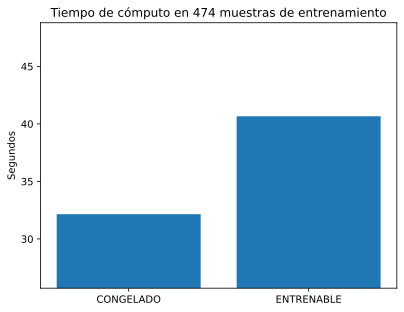

In [23]:
# Tiempo de cómputo
plt.bar([1, 2], [timeFreeze, timeTrain])
plt.gca().set(
    xticks=[1, 2],
    xticklabels=['CONGELADO', 'ENTRENABLE'],
    ylim=[
        min(timeFreeze, timeTrain) * 0.8,
        max(timeFreeze, timeTrain) * 1.2,
    ],  # Ajustado dinámicamente para visualizar mejor la diferencia
    title=f'Tiempo de cómputo en {num_samples} muestras de entrenamiento',
    ylabel='Segundos',
)
plt.show()

### Análisis del Tiempo de Cómputo

Esta es la suma de los 474 *epochs* o iteraciones en el modelo, por lo que ahorramos una cantidad considerable de tiempo de cálculo.

Por otro lado, hay que tener en cuenta que gran parte del cálculo y del tiempo de computación que implica el entrenamiento de un modelo lingüístico de gran tamaño (LLM) procede de la pasada hacia adelante (*forward pass*), del cálculo de la pérdida y de un montón de gastos generales (*overhead*). Así que congelar gran parte del modelo ayuda a reducir el tiempo de cálculo, aunque no provoca un efecto desproporcionadamente enorme.

In [24]:
# Para hacer una interpretacion basta con invertir el filtrado de parametros entrenables y congelados.

###  Inversión de la Estrategia Experimental

Ahora vamos a entrenar la gran mayoría del modelo y a congelar únicamente las matrices de atención dentro de los bloques de transformadores posteriores (`transformer blocks`), modificando selectivamente los parámetros de `requires_grad`.

In [25]:
# Invertir la estrategia: Entrenar todo el modelo, pero congelar las matrices de atención en capas > 5

for name, param in modelFreeze.named_parameters():
  splitstr = name.split('.')

  # Verificar si cumple con los criterios de las matrices de atención en capas > 5
  if (len(splitstr) > 5) and (splitstr[3] == 'attn'):
    if (int(splitstr[2]) > 5) and (splitstr[5][0] in 'qvk'):
      # CONGELAR estas matrices específicas
      param.requires_grad = False
      print(
          f'--- La capa de atención {name} está congelada (.requires_grad ='
          f' {param.requires_grad})'
      )
      continue

  # ENTRENAR el resto del modelo
  param.requires_grad = True
  print(
      f'+++ La capa {name} es entrenable (.requires_grad ='
      f' {param.requires_grad}).'
  )

+++ La capa transformer.wte.weight es entrenable (.requires_grad = True).
+++ La capa transformer.wpe.weight es entrenable (.requires_grad = True).
+++ La capa transformer.h.0.ln_1.weight es entrenable (.requires_grad = True).
+++ La capa transformer.h.0.ln_1.bias es entrenable (.requires_grad = True).
+++ La capa transformer.h.0.attn.attention.k_proj.weight es entrenable (.requires_grad = True).
+++ La capa transformer.h.0.attn.attention.v_proj.weight es entrenable (.requires_grad = True).
+++ La capa transformer.h.0.attn.attention.q_proj.weight es entrenable (.requires_grad = True).
+++ La capa transformer.h.0.attn.attention.out_proj.weight es entrenable (.requires_grad = True).
+++ La capa transformer.h.0.attn.attention.out_proj.bias es entrenable (.requires_grad = True).
+++ La capa transformer.h.0.ln_2.weight es entrenable (.requires_grad = True).
+++ La capa transformer.h.0.ln_2.bias es entrenable (.requires_grad = True).
+++ La capa transformer.h.0.mlp.c_fc.weight es entrenable 

In [26]:
# Crear los optimizadores para ambos modelos
optimizerFreeze = torch.optim.AdamW(modelFreeze.parameters(), lr=0.0005)
optimizerTrain = torch.optim.AdamW(modelTrain.parameters(), lr=0.0005)

# Inicializar pérdidas y tiempos
losses = np.zeros((num_samples, 2))
delta_norm_em = np.zeros((num_samples, 2))
timeTrain = 0
timeFreeze = 0

# Capturar pesos iniciales de k_proj para comparación
prev_emFreeze = (
    modelFreeze.transformer.h[6]
    .attn.attention.k_proj.weight.detach()
    .clone()
)
prev_emTrain = (
    modelTrain.transformer.h[6].attn.attention.k_proj.weight.detach().clone()
)

# Ejecutar el ciclo de entrenamiento
for sampli in range(num_samples):

  # Obtener un lote de datos
  ix = torch.randint(len(tokens) - seq_len, size=(batch_size,))
  X = tokens[ix[:, None] + torch.arange(seq_len)].to(device)

  ### --- Modelo CONGELADO (Invertido) ---
  start_time = time.time()
  modelFreeze.zero_grad()
  outputs = modelFreeze(X, labels=X)
  outputs.loss.backward()
  optimizerFreeze.step()
  losses[sampli, 0] = outputs.loss.item()
  timeFreeze += time.time() - start_time

  ### --- Modelo ENTRENABLE (Completo) ---
  start_time = time.time()
  modelTrain.zero_grad()
  outputs = modelTrain(X, labels=X)
  outputs.loss.backward()
  optimizerTrain.step()
  losses[sampli, 1] = outputs.loss.item()
  timeTrain += time.time() - start_time

  # Calcular la norma del cambio en la matriz de atención
  delta_norm_em[sampli, 0] = torch.norm(
      modelFreeze.transformer.h[6].attn.attention.k_proj.weight.detach()
      - prev_emFreeze
  )
  prev_emFreeze = (
      modelFreeze.transformer.h[6]
      .attn.attention.k_proj.weight.detach()
      .clone()
  )

  delta_norm_em[sampli, 1] = torch.norm(
      modelTrain.transformer.h[6].attn.attention.k_proj.weight.detach()
      - prev_emTrain
  )
  prev_emTrain = (
      modelTrain.transformer.h[6].attn.attention.k_proj.weight.detach().clone()
  )

  # Mostrar progreso en consola
  if sampli % 37 == 0:
    print(
        f'Muestra {sampli:4}/{num_samples}, pérdidas (Congelado/Entrenable):'
        f' {losses[sampli, 0]:.4f} / {losses[sampli, 1]:.4f}'
    )

Muestra    0/474, pérdidas (Congelado/Entrenable): 2.3597 / 1.1226
Muestra   37/474, pérdidas (Congelado/Entrenable): 2.6166 / 1.0886
Muestra   74/474, pérdidas (Congelado/Entrenable): 2.4358 / 1.1395
Muestra  111/474, pérdidas (Congelado/Entrenable): 2.3263 / 0.9588
Muestra  148/474, pérdidas (Congelado/Entrenable): 1.6008 / 0.6186
Muestra  185/474, pérdidas (Congelado/Entrenable): 2.1087 / 0.9005
Muestra  222/474, pérdidas (Congelado/Entrenable): 1.8891 / 0.6304
Muestra  259/474, pérdidas (Congelado/Entrenable): 1.4637 / 0.4546
Muestra  296/474, pérdidas (Congelado/Entrenable): 1.1700 / 0.3688
Muestra  333/474, pérdidas (Congelado/Entrenable): 1.0857 / 0.3542
Muestra  370/474, pérdidas (Congelado/Entrenable): 1.1187 / 0.3523
Muestra  407/474, pérdidas (Congelado/Entrenable): 1.0361 / 0.3492
Muestra  444/474, pérdidas (Congelado/Entrenable): 1.1808 / 0.4257


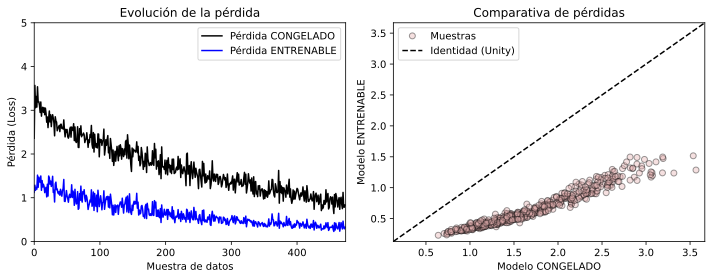

In [28]:
# graficar las pérdidas
_, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(losses[:, 0], 'k', markersize=8, label='Pérdida CONGELADO')
axs[0].plot(losses[:, 1], 'b', markersize=8, label='Pérdida ENTRENABLE')
axs[0].legend()
axs[0].set(
    ylim=[0, 5],
    xlabel='Muestra de datos',
    ylabel='Pérdida (Loss)',
    xlim=[0, num_samples],
    title='Evolución de la pérdida',
)

axs[1].plot(
    losses[:, 0],
    losses[:, 1],
    'ko',
    markerfacecolor=[0.9, 0.7, 0.7],
    alpha=0.4,
    label='Muestras',
)
xylim = [np.min(losses) - 0.1, np.max(losses) + 0.1]
axs[1].plot(xylim, xylim, 'k--', zorder=-3, label='Identidad (Unity)')
axs[1].set(
    xlabel='Modelo CONGELADO',
    ylabel='Modelo ENTRENABLE',
    title='Comparativa de pérdidas',
    xlim=xylim,
    ylim=xylim,
)
axs[1].legend()

plt.tight_layout()
plt.show()

## Sin Congelación

Muestra    0/474, pérdidas (Freeze/Train): 0.3075 / 0.1961
Muestra   37/474, pérdidas (Freeze/Train): 0.4083 / 0.2474
Muestra   74/474, pérdidas (Freeze/Train): 0.3214 / 0.2084
Muestra  111/474, pérdidas (Freeze/Train): 0.3558 / 0.2383
Muestra  148/474, pérdidas (Freeze/Train): 0.3797 / 0.2648
Muestra  185/474, pérdidas (Freeze/Train): 0.3149 / 0.2131
Muestra  222/474, pérdidas (Freeze/Train): 0.3106 / 0.2319
Muestra  259/474, pérdidas (Freeze/Train): 0.2748 / 0.2111
Muestra  296/474, pérdidas (Freeze/Train): 0.2757 / 0.2016
Muestra  333/474, pérdidas (Freeze/Train): 0.2274 / 0.1852
Muestra  370/474, pérdidas (Freeze/Train): 0.2207 / 0.1701
Muestra  407/474, pérdidas (Freeze/Train): 0.2377 / 0.1766
Muestra  444/474, pérdidas (Freeze/Train): 0.2124 / 0.1765


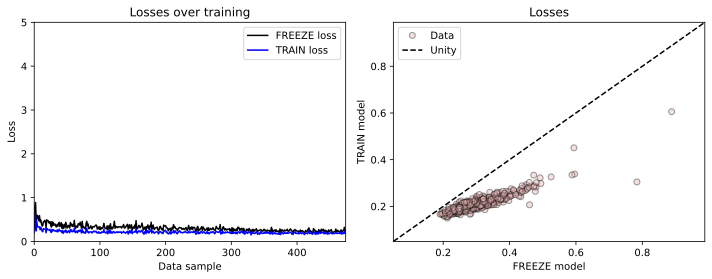

In [30]:
# Asegurar que ambos modelos sean 100% entrenables (sin congelaciones) para obtener la paridad exacta
for name, param in modelFreeze.named_parameters():
  param.requires_grad = True

for name, param in modelTrain.named_parameters():
  param.requires_grad = True

# Recrear los optimizadores
optimizerFreeze = torch.optim.AdamW(modelFreeze.parameters(), lr=0.0005)
optimizerTrain = torch.optim.AdamW(modelTrain.parameters(), lr=0.0005)

# Inicializar matrices para métricas
losses = np.zeros((num_samples, 2))
delta_norm_em = np.zeros((num_samples, 2))
timeTrain = 0
timeFreeze = 0

prev_emFreeze = (
    modelFreeze.transformer.h[6]
    .attn.attention.k_proj.weight.detach()
    .clone()
)
prev_emTrain = (
    modelTrain.transformer.h[6].attn.attention.k_proj.weight.detach().clone()
)

# Ciclo de entrenamiento
for sampli in range(num_samples):
  ix = torch.randint(len(tokens) - seq_len, size=(batch_size,))
  X = tokens[ix[:, None] + torch.arange(seq_len)].to(device)

  # --- Modelo FREEZE (Copia idéntica) ---
  start_time = time.time()
  modelFreeze.zero_grad()
  outputs = modelFreeze(X, labels=X)
  outputs.loss.backward()
  optimizerFreeze.step()
  losses[sampli, 0] = outputs.loss.item()
  timeFreeze += time.time() - start_time

  # --- Modelo TRAIN ---
  start_time = time.time()
  modelTrain.zero_grad()
  outputs = modelTrain(X, labels=X)
  outputs.loss.backward()
  optimizerTrain.step()
  losses[sampli, 1] = outputs.loss.item()
  timeTrain += time.time() - start_time

  delta_norm_em[sampli, 0] = torch.norm(
      modelFreeze.transformer.h[6].attn.attention.k_proj.weight.detach()
      - prev_emFreeze
  )
  prev_emFreeze = (
      modelFreeze.transformer.h[6]
      .attn.attention.k_proj.weight.detach()
      .clone()
  )

  delta_norm_em[sampli, 1] = torch.norm(
      modelTrain.transformer.h[6].attn.attention.k_proj.weight.detach()
      - prev_emTrain
  )
  prev_emTrain = (
      modelTrain.transformer.h[6].attn.attention.k_proj.weight.detach().clone()
  )

  if sampli % 37 == 0:
    print(
        f'Muestra {sampli:4}/{num_samples}, pérdidas (Freeze/Train):'
        f' {losses[sampli, 0]:.4f} / {losses[sampli, 1]:.4f}'
    )

# Graficar exactamente con el formato original
_, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].plot(losses[:, 0], 'k', markersize=8, label='FREEZE loss')
axs[0].plot(losses[:, 1], 'b', markersize=8, label='TRAIN loss')
axs[0].legend()
axs[0].set(
    ylim=[0, 5],
    xlabel='Data sample',
    ylabel='Loss',
    xlim=[0, num_samples],
    title='Losses over training',
)

axs[1].plot(
    losses[:, 0],
    losses[:, 1],
    'ko',
    markerfacecolor=[0.9, 0.7, 0.7],
    alpha=0.4,
    label='Data',
)
xylim = [np.min(losses) - 0.1, np.max(losses) + 0.1]
axs[1].plot(xylim, xylim, 'k--', zorder=-3, label='Unity')
axs[1].set(
    xlabel='FREEZE model',
    ylabel='TRAIN model',
    title='Losses',
    xlim=xylim,
    ylim=xylim,
)
axs[1].legend()

plt.tight_layout()
plt.show()